# RepX: Exercise Classifier
This notebook trains the AI that **names the exercise** from the camera and compares **3 classification techniques**: K-Nearest Neighbours, Decision Tree and Random Forest.

**Dataset:** the Kaggle *Workout/Exercises Video* dataset. We ran every video through MediaPipe (`make_dataset.py`), turned the body points into 6 joint angles, and cut each video into 1.6-second windows. Each window is one row of `exercise_data.csv`: the exercise name, the video it came from, and 36 numbers.

Run the cells from top to bottom (**Run → Run All Cells**).

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Load the dataset
If `exercise_data.csv` is next to this notebook it is used, otherwise it is downloaded from our GitHub.

In [2]:
import os

if os.path.exists("exercise_data.csv"):
    data = pd.read_csv("exercise_data.csv")
else:
    data = pd.read_csv("https://raw.githubusercontent.com/YTM77/RepX/main/exercise_data.csv")

print("Rows (1.6 s windows):", len(data))
print("Videos:", data["video"].nunique())
data.head()

Rows (1.6 s windows): 4195
Videos: 133


,exercise,video,knee_mean,knee_std,knee_min,knee_max,knee_range,knee_speed,hip_mean,hip_std,...,trunk_lean_min,trunk_lean_max,trunk_lean_range,trunk_lean_speed,body_line_mean,body_line_std,body_line_min,body_line_max,body_line_range,body_line_speed
0,plank,plank/plank_1.MOV,173.46,0.67,172.05,174.59,2.54,0.16,162.44,1.19,...,95.65,99.01,3.36,0.14,89.07,0.61,88.46,90.25,1.79,0.06
1,plank,plank/plank_1.MOV,173.29,0.82,171.80,174.59,2.79,0.15,162.37,1.26,...,95.65,98.17,2.52,0.12,88.85,0.43,88.46,90.14,1.68,0.05
2,plank,plank/plank_1.MOV,172.91,0.74,171.77,174.23,2.46,0.16,162.14,1.26,...,95.65,97.85,2.20,0.12,88.66,0.19,88.23,89.28,1.05,0.04
3,plank,plank/plank_1.MOV,172.47,0.79,170.59,173.88,3.29,0.19,161.87,1.05,...,93.65,97.85,4.20,0.15,88.33,0.69,85.84,88.83,2.99,0.08
4,plank,plank/plank_1.MOV,172.27,0.78,170.59,173.59,3.00,0.23,161.68,0.81,...,91.27,97.85,6.58,0.19,87.60,1.73,83.01,88.83,5.82,0.13


## 3. What is inside
How many windows and videos we have for each exercise.

In [3]:
summary = pd.DataFrame({
    "windows": data["exercise"].value_counts(),
    "videos": data.groupby("exercise")["video"].nunique(),
})
summary

,windows,videos
exercise,,
plank,1193,7
pull_up,620,25
push_up,922,56
shoulder_press,555,17
squat,905,28


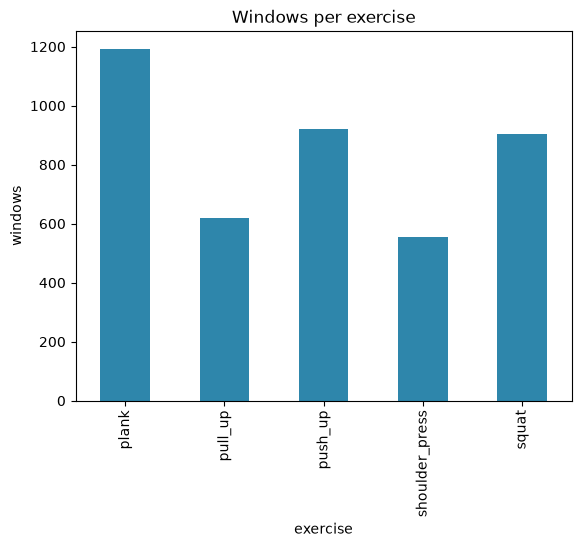

In [4]:
summary["windows"].plot(kind="bar", color="#2E86AB", title="Windows per exercise")
plt.ylabel("windows")
plt.show()

## 4. Split into training and testing
We split by **video**, not by row: 1 in every 5 videos is kept apart for testing.
So no piece of a test video is ever seen during training. The score is on videos the model never saw.

In [5]:
videos = sorted(data["video"].unique())
test_videos = videos[::5]
train = data[~data["video"].isin(test_videos)]
test = data[data["video"].isin(test_videos)]

X_train = train.drop(columns=["exercise", "video"]).to_numpy()
y_train = train["exercise"].to_numpy()
X_test = test.drop(columns=["exercise", "video"]).to_numpy()
y_test = test["exercise"].to_numpy()

print("Training:", len(train), "windows from", train["video"].nunique(), "videos")
print("Testing: ", len(test), "windows from", len(test_videos), "videos")

Training: 3443 windows from 106 videos
Testing:  752 windows from 27 videos


## 5. Train the 3 classifiers
* **K-Nearest Neighbours:** finds the 5 most similar training windows and lets them vote.
* **Decision Tree:** learns one list of yes/no questions about the angles.
* **Random Forest:** builds 100 different trees and lets them vote.

In [6]:
models = {
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=0),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained", name)

Trained K-Nearest Neighbours
Trained Decision Tree


Trained Random Forest


## 6. Accuracy on videos the models never saw

In [7]:
results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    results.append({
        "classifier": name,
        "accuracy on training data %": round(accuracy_score(y_train, model.predict(X_train)) * 100, 1),
        "accuracy on new videos %": round(accuracy_score(y_test, predictions) * 100, 1),
    })

results = pd.DataFrame(results).set_index("classifier")
results

,accuracy on training data %,accuracy on new videos %
classifier,,
K-Nearest Neighbours,99.2,83.9
Decision Tree,100.0,80.7
Random Forest,100.0,87.8


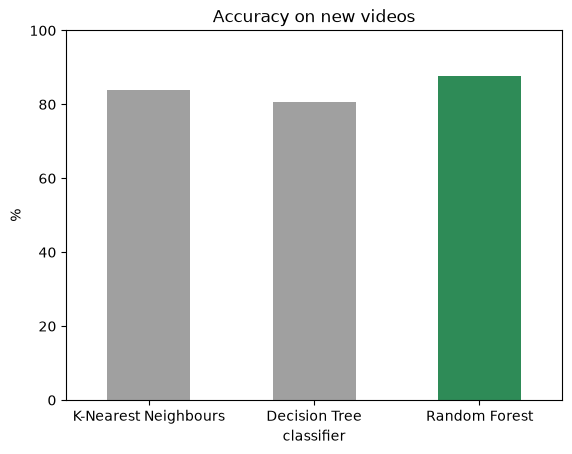

In [8]:
results["accuracy on new videos %"].plot(kind="bar", color=["#A0A0A0", "#A0A0A0", "#2E8B57"],
                                         title="Accuracy on new videos", ylim=(0, 100))
plt.ylabel("%")
plt.xticks(rotation=0)
plt.show()

**Training vs new videos:** the Decision Tree gets 100% on training data but much less on new videos, which means it **memorised** instead of learning.
Random Forest also fits the training data, but 100 voting trees cancel each other's mistakes, so it does best on new videos.

## 7. Mistakes table (confusion matrix) for each classifier
Rows are the real exercise, columns are what the model guessed. Numbers on the diagonal are correct.

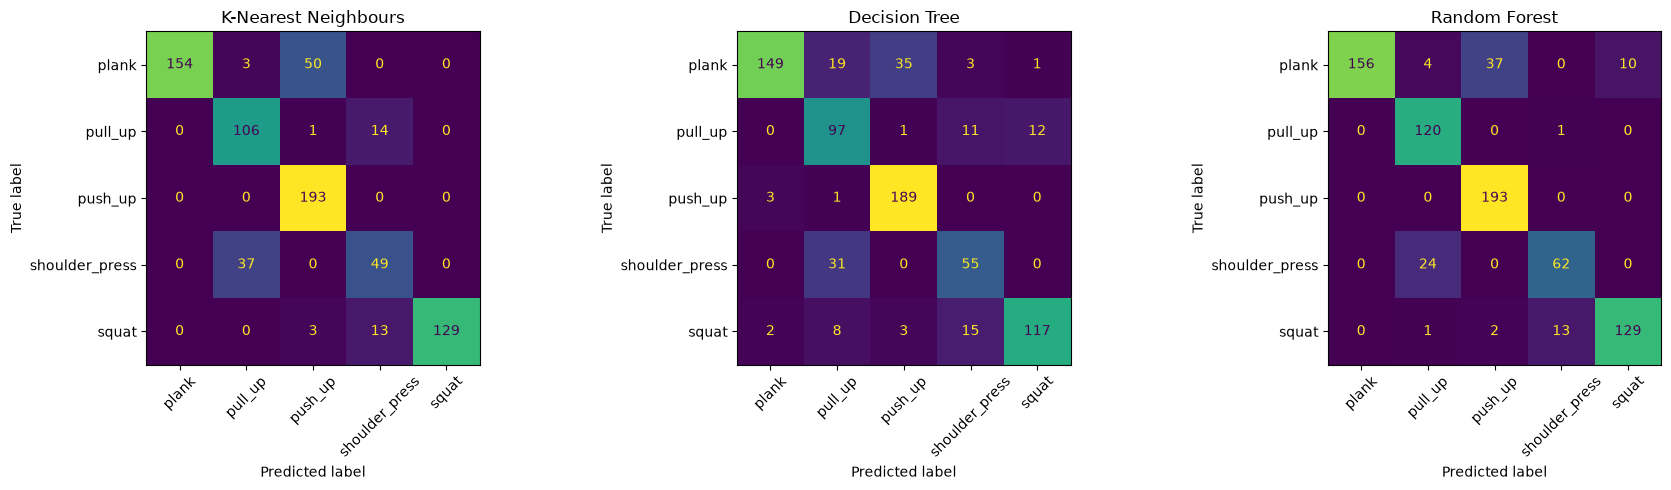

In [9]:
labels = sorted(data["exercise"].unique())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, models.items()):
    table = confusion_matrix(y_test, model.predict(X_test), labels=labels)
    ConfusionMatrixDisplay(table, display_labels=labels).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 8. Accuracy for each exercise

In [10]:
per_exercise = {}
for name, model in models.items():
    table = confusion_matrix(y_test, model.predict(X_test), labels=labels)
    per_exercise[name] = [round(table[i, i] / table[i].sum() * 100, 1) for i in range(len(labels))]

pd.DataFrame(per_exercise, index=labels)

,K-Nearest Neighbours,Decision Tree,Random Forest
plank,74.4,72.0,75.4
pull_up,87.6,80.2,99.2
push_up,100.0,97.9,100.0
shoulder_press,57.0,64.0,72.1
squat,89.0,80.7,89.0


## 9. Extra checks
* **Whole videos correct:** for each test video, take the most common guess over all its windows.
* **Right when at least 70% sure:** the live app only shows the exercise name when the model is at least 70% sure (3 times in a row), so this tells us how trustworthy the name on screen is.
* **Time per guess:** how long one guess takes. The app guesses about every 0.27 seconds.

In [11]:
extra = []
for name, model in models.items():
    predictions = model.predict(X_test)
    votes = pd.DataFrame({"video": test["video"], "real": y_test, "guess": predictions})
    by_video = votes.groupby("video").agg(real=("real", "first"), guess=("guess", lambda g: g.mode()[0]))
    videos_correct = (by_video["real"] == by_video["guess"]).sum()

    confidence = model.predict_proba(X_test).max(axis=1)
    sure = confidence >= 0.7
    right_when_sure = (predictions[sure] == y_test[sure]).mean()

    start = time.time()
    for i in range(200):
        model.predict_proba(X_test[i:i + 1])
    ms = (time.time() - start) / 200 * 1000

    extra.append({
        "classifier": name,
        "whole videos correct": str(videos_correct) + " of " + str(len(by_video)),
        "right when ≥70% sure %": round(right_when_sure * 100, 1),
        "time per guess (ms)": round(ms, 2),
    })

pd.DataFrame(extra).set_index("classifier")

,whole videos correct,right when ≥70% sure %,time per guess (ms)
classifier,,,
K-Nearest Neighbours,25 of 27,84.4,0.64
Decision Tree,23 of 27,80.7,0.08
Random Forest,26 of 27,99.8,4.68


## 10. What the Random Forest looks at most
The 10 most useful of the 36 numbers.

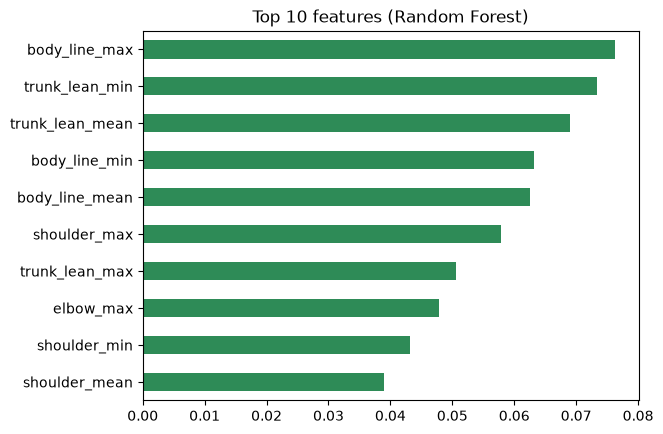

In [12]:
forest = models["Random Forest"]
names = train.drop(columns=["exercise", "video"]).columns
importance = pd.Series(forest.feature_importances_, index=names).sort_values().tail(10)
importance.plot(kind="barh", color="#2E8B57", title="Top 10 features (Random Forest)")
plt.show()

## 11. Conclusion: why we picked Random Forest
1. **Most accurate** on videos it never saw (section 6).
2. **Best or tied best on every exercise**, especially pull-up and shoulder press (section 8).
3. **Trustworthy:** when it is at least 70% sure, it is almost always right, and that is exactly when the app shows the name (section 9).
4. **Doesn't memorise** like a single Decision Tree (section 6).
5. **Fast enough** for a live camera: a few milliseconds per guess (section 9).

The saved model (`exercise_model.pkl`) is what `main.py` uses in the live demo.